import carla

In [4]:
import carla
import numpy as np
import time
import queue
import cv2
from datetime import datetime

client = carla.Client('localhost', 2000)
client.set_timeout(10.0)  # seconds
world = client.load_world("Town02")
def save_bird_eye_image(client, trajectory_waypoints, output_filename=None, image_size=(1920, 1080)):
   

   town_center_x = 0
   town_center_y = 0
   town_center_z = 0
  
   # Set a fixed camera height that shows the entire town
   view_height = 200  # Meters above town center
  
   # Set up blueprint library
   blueprint_library = world.get_blueprint_library()
  
   # Get the camera sensor blueprint
   camera_bp = blueprint_library.find('sensor.camera.rgb')
  
   # Set camera attributes for higher FOV to see more of the town
   camera_bp.set_attribute('image_size_x', str(image_size[0]))
   camera_bp.set_attribute('image_size_y', str(image_size[1]))
   camera_bp.set_attribute('fov', '120')  # Wider field of view
  
   # Set up camera transform at bird's eye view over town center
   camera_transform = carla.Transform(
       carla.Location(x=town_center_x, y=town_center_y, z=town_center_z + view_height),
       carla.Rotation(pitch=-90, yaw=0, roll=0)  # Looking straight down
   )
  
   # Create a camera actor
   camera = world.spawn_actor(camera_bp, camera_transform)
   print(f"Camera positioned at height {view_height:.2f} meters above town center")
  
   # Also set spectator to same position for visualization
   spectator = world.get_spectator()
   spectator.set_transform(camera_transform)
  
   # Draw the trajectory for visualization
   debug = world.debug
  
  
   # Draw start and end points with larger, more visible spheres
   for location in locations:
       debug.draw_point(
           location,
           size=2.0,  # Larger point
           color=carla.Color(0, 255, 0),  # Green
           life_time=20.0
       )
      
      
   # Set up a queue to capture the image
   image_queue = queue.Queue()
  
   # Callback function to save the image
   def camera_callback(image):
       image_queue.put(image)
  
   # Register the callback function
   camera.listen(camera_callback)
  
   # Generate default filename if not provided
   if output_filename is None:
       timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
       output_filename = f"carla_trajectory_birdeye_{timestamp}.jpg"
  
   # Wait a moment for rendering and capture the image
   print("Waiting for camera to capture image...")
   time.sleep(2.0)  # Allow more time for rendering
  
   try:
       # Get the image from the queue
       image = image_queue.get(timeout=5.0)  # Longer timeout
      
       # Convert the image to a usable format
       array = np.frombuffer(image.raw_data, dtype=np.dtype("uint8"))
       array = np.reshape(array, (image.height, image.width, 4))
       array = array[:, :, :3]  # Remove the alpha channel
      
       # Optional: Enhance image for better visibility
       # Increase brightness and contrast slightly
       array = np.clip(array * 1.2, 0, 255).astype(np.uint8)
      
       # Save the image using OpenCV
       cv2.imwrite(output_filename, array)
       print(f"Image saved as {output_filename}")
      
   except queue.Empty:
       print("Failed to capture image (timeout)")
   finally:
       # Clean up
       camera.stop()
       camera.destroy()
       print("Camera destroyed")



: 

In [3]:
import pickle
import carla
with open("/home/robotlab/scratch/carla-rl/full_traj_aux.pkl", 'rb') as handle:
            user_defined_trajectories=pickle.load(handle)
            locations=user_defined_trajectories["locations"]
            print(locations)
            for (start,goal) in locations:
                location=start
                origin=carla.Location(x=location[0],y=location[1],z=location[2])
                location=goal
                destination=carla.Location(x=location[0],y=location[1],z=location[2])

[[array([ 13.09908104, 191.5582428 ,   0.        ]), array([101.30137634, 105.42549133,   0.        ])], [array([ -3.44036579, 248.99957275,   0.        ]), array([193.69578552, 256.88137817,   0.        ])], [array([ -3.45081949, 202.69958496,   0.        ]), array([ 65.8013916, 105.4013443,   0.       ])], [array([ -3.44059134, 247.99957275,   0.        ]), array([ -3.40469956, 137.44459534,   0.        ])], [array([ -3.4446106 , 230.19958496,   0.        ]), array([119.35930634, 306.5539856 ,   0.        ])]]


In [18]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches

def plot_carla_location_pairs(image_path, location_pairs, img_width=None, img_height=None, 
                             carla_bounds=None, colors=None, marker_size=90, 
                             save_path=None, line_color='red', 
                             line_style='-', line_width=2):
    """
    Plot pairs of CARLA locations on the given image.
    
    Parameters:
    -----------
    image_path : str
        Path to the image file
    location_pairs : list of pairs of arrays
        List of pairs of [x, y, z] CARLA coordinate arrays
    img_width : int, optional
        Width of the image in pixels (if None, will be determined from image)
    img_height : int, optional
        Height of the image in pixels (if None, will be determined from image)
    carla_bounds : tuple, optional
        (min_x, min_y, max_x, max_y) CARLA world coordinates visible in the image
        If None, uses calculated bounds from data
    colors : list of str, optional
        Colors for each location pair
    marker_size : int, optional
        Size of the markers
    save_path : str, optional
        Path to save the output image
    line_color : str, optional
        Color of the lines connecting points
    line_style : str, optional
        Style of the lines connecting points
    line_width : int, optional
        Width of the lines connecting points
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    # Load the image
    img = plt.imread(image_path)
    
    # Get image dimensions
    if img_height is None or img_width is None:
        img_height, img_width = img.shape[:2]
    
    # Extract all points for determining bounds if not provided
    all_points = []
    for pair in location_pairs:
        all_points.append((pair[0][0], pair[0][1]))
        all_points.append((pair[1][0], pair[1][1]))
    
    # Calculate bounds from data if not provided
    if carla_bounds is None:
        xs = [p[0] for p in all_points]
        ys = [p[1] for p in all_points]
        
        # Add some padding to the bounds
        padding = 5
        min_x = min(xs) - padding
        max_x = max(xs) + padding
        min_y = min(ys) - padding
        max_y = max(ys) + padding
        
        carla_bounds = (min_x, min_y, max_x, max_y)
    
    # Function to convert CARLA coordinates to pixel coordinates
    def carla_to_pixel(carla_pos):
        carla_x, carla_y = carla_pos[0], carla_pos[1]  # Ignore z-coordinate
        min_x, min_y, max_x, max_y = carla_bounds
        
        # The y-axis might be inverted between CARLA and image coordinates
        pixel_x = ((carla_x - min_x) / (max_x - min_x)) * img_width
        pixel_y = ((max_y - carla_y) / (max_y - min_y)) * img_height  # Note the inversion
        
        return (pixel_x, pixel_y)
    
    # Default colors if not provided
    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, len(location_pairs)))
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=(12, 12))
    
    # Display the image
    ax.imshow(img)
    
    # Plot each location pair
    for i, pair in enumerate(location_pairs):
        start_pos = pair[0]
        end_pos = pair[1]
        
        # Convert to pixel coordinates
        start_pixel = carla_to_pixel(start_pos)
        end_pixel = carla_to_pixel(end_pos)
        
        # Plot start and end points
        color = colors[i] if isinstance(colors[i], str) else colors[i]
        ax.scatter(start_pixel[0], start_pixel[1], c='green', s=marker_size, 
                  marker='o', edgecolor='black', zorder=5)
        ax.scatter(end_pixel[0], end_pixel[1], c='red', s=marker_size, 
                  marker='o', edgecolor='black', zorder=5)
        
        # # Draw line between them
        # ax.plot([start_pixel[0], end_pixel[0]], [start_pixel[1], end_pixel[1]], 
        #        color=line_color, linestyle=line_style, linewidth=line_width, zorder=4)
        
        # Add pair number for reference
        # mid_x = (start_pixel[0] + end_pixel[0]) / 2
        # mid_y = (start_pixel[1] + end_pixel[1]) / 2
        # ax.text(mid_x, mid_y, f"Pair {i+1}", fontsize=12, color='white',
        #        bbox=dict(facecolor='black', alpha=0.7, edgecolor='none'))
    
    # Add a grid for reference
    ax.grid(False)
    
    # Remove axis ticks
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Title
    # ax.set_title('CARLA Navigation Path Pairs', fontsize=16)
    
    # # Add bounds info for debugging
    # min_x, min_y, max_x, max_y = carla_bounds
    # ax.text(10, img_height-20, 
    #         f"CARLA Bounds: ({min_x:.1f}, {min_y:.1f}) to ({max_x:.1f}, {max_y:.1f})", 
    #         fontsize=10, color='white', bbox=dict(facecolor='black', alpha=0.7))
    
    plt.tight_layout()
    
    # Save if path is provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig, ax

# For using with your specific data format
def plot_node_pairs_from_arrays(image_path, array_data, save_path=None):
    """
    Plot the node pairs from the provided array data format
    
    Parameters:
    -----------
    image_path : str
        Path to the image file
    array_data : list of pairs of numpy arrays
        Data in the format provided in your question
    save_path : str, optional
        Path to save the output image
    """
    # Verify data format
    location_pairs = []
    for pair in array_data:
        if len(pair) == 2 and isinstance(pair[0], np.ndarray) and isinstance(pair[1], np.ndarray):
            location_pairs.append(pair)
        else:
            print(f"Warning: Skipping invalid pair format: {pair}")
    
    # Use different colors for different pairs
    colors = ['blue', 'red', 'green', 'purple', 'orange', 'cyan', 'magenta', 'yellow']
    
    return plot_carla_location_pairs(image_path, location_pairs, colors=colors, 
                                    line_width=2, save_path=save_path)

# Example usage with your provided data
if __name__ == "__main__":
    # Convert your data to the right format
    with open(f'/home/robotlab/scratch/carla-rl/baseline_maps/vint/aux.pkl', 'rb') as handle:
            dataset=pickle.load(handle)
    locations=np.array(list(dataset["locations"].values()))
    data = locations
    print(data)
    # Plot the data
    fig, ax = plot_node_pairs_from_arrays("/home/robotlab/scratch/carla-rl/town02aerial.jpg", data, save_path="vint_global_map.png")
    
    plt.show()

[[181.39863586 105.42006683   0.        ]
 [181.29864502 105.4201355    0.        ]
 [181.19863892 105.42020416   0.        ]
 ...
 [ 41.8533287  227.8001709    0.        ]
 [ 41.85332108 227.70018005   0.        ]
 [ 41.85331345 227.60017395   0.        ]]


ValueError: min() arg is an empty sequence

/tmp/ipykernel_2822933/519159857.py:92: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')


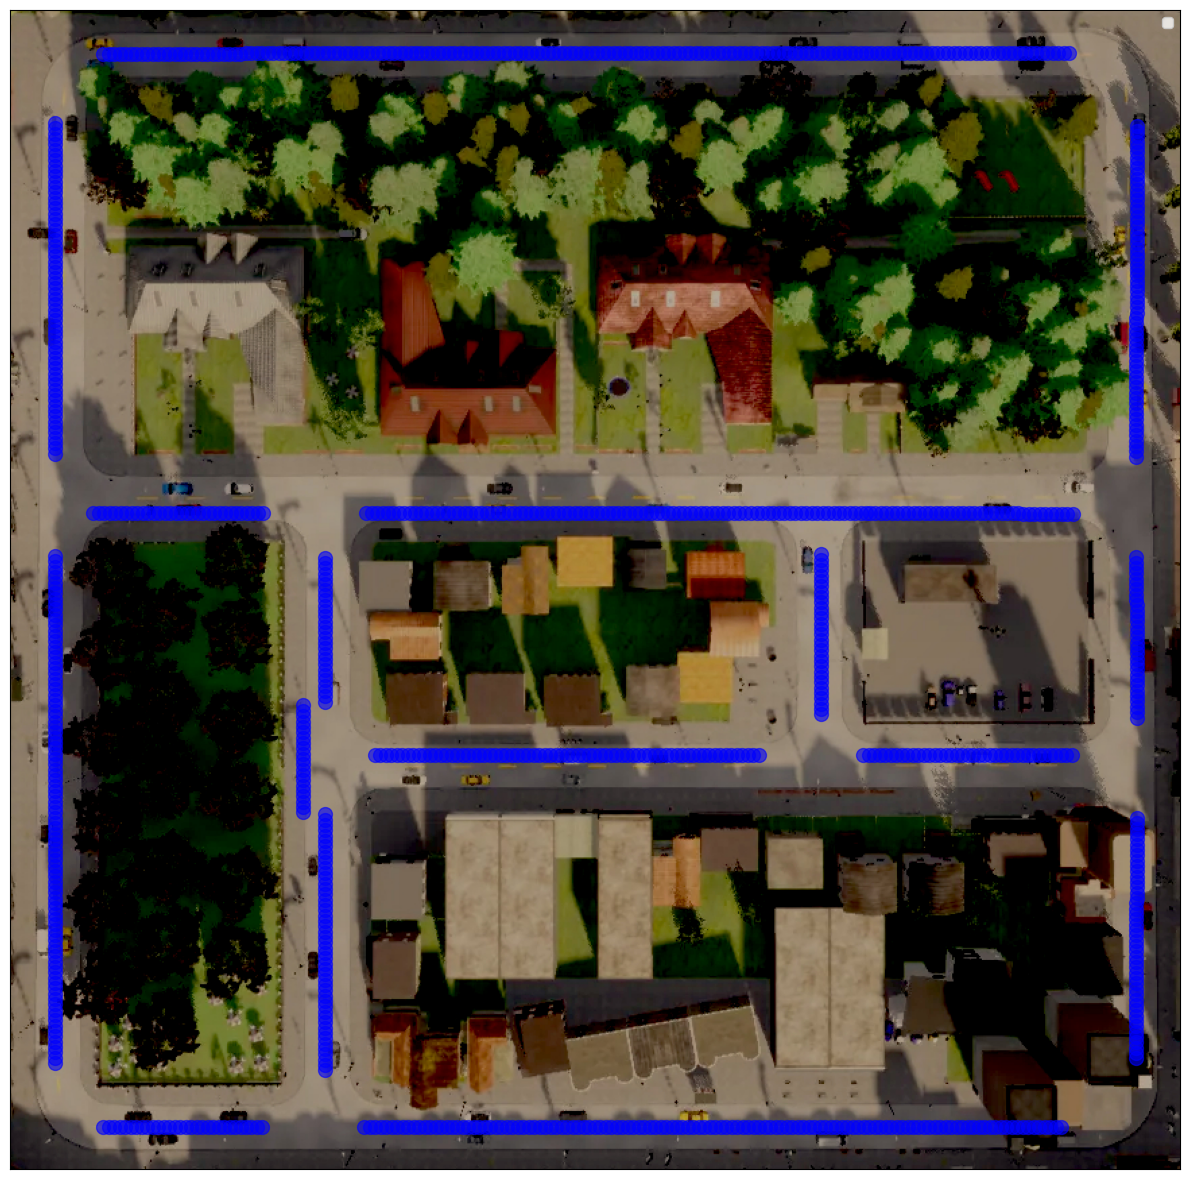

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches

def plot_carla_trajectory(image_path, trajectory, img_width=None, img_height=None, 
                         carla_bounds=None, point_color='blue', line_color='red',
                         marker_size=10000, save_path=None, show_all_points=True,
                         point_density=20):
    """
    Plot a trajectory of CARLA locations on the given image with proper vertical alignment.
    """
    # Load the image
    img = plt.imread(image_path)
    
    # Get image dimensions
    if img_height is None or img_width is None:
        img_height, img_width = img.shape[:2]
    
    # Extract all points for determining bounds if not provided
    points = [(point[0], point[1]) for point in trajectory]
    
    # Calculate bounds from data if not provided
    if carla_bounds is None:
        xs = [p[0] for p in points]
        ys = [p[1] for p in points]
        
        # Add padding to the bounds
        padding = 8
        min_x = min(xs) - padding
        max_x = max(xs) + padding
        min_y = min(ys) - padding
        max_y = max(ys) + padding
        
        carla_bounds = (min_x, min_y, max_x, max_y)
    
    # Function to convert CARLA coordinates to pixel coordinates
    # FIXED VERSION - Note the y-coordinate transformation!
    def carla_to_pixel(carla_pos):
        carla_x, carla_y = carla_pos[0], carla_pos[1]  # Ignore z-coordinate
        min_x, min_y, max_x, max_y = carla_bounds
        
        # Calculate normal pixel coordinates
        pixel_x = ((carla_x - min_x) / (max_x - min_x)) * img_width
        
        # FIXED: Now we directly map y without inverting
        # This assumes the CARLA coordinates have y increasing downward
        pixel_y = ((carla_y - min_y) / (max_y - min_y)) * img_height
        
        return (pixel_x, pixel_y)
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=(12, 12))
    
    # Display the image
    ax.imshow(img)
    
    # Convert all points to pixel coordinates
    pixel_points = [carla_to_pixel(point) for point in trajectory]
    
    # # Plot the trajectory line
    # x_coords = [p[0] for p in pixel_points]
    # y_coords = [p[1] for p in pixel_points]
    # ax.plot(x_coords, y_coords, color=line_color, linewidth=2, zorder=3)
    
    # Plot individual points - either all or sampled
    if show_all_points:
        points_to_plot = pixel_points
    else:
        points_to_plot = pixel_points[::point_density]  # Sample every nth point
    
    for i, (px, py) in enumerate(points_to_plot):
        ax.scatter(px, py, c=point_color, s=marker_size, marker='o', alpha=0.6, zorder=4)
    
    # # Highlight start and end points
    # ax.scatter(pixel_points[0][0], pixel_points[0][1], c='green', s=marker_size*10, 
    #           marker='o', edgecolor='black', zorder=5, label='Start')
    # ax.scatter(pixel_points[-1][0], pixel_points[-1][1], c='red', s=marker_size*10, 
    #           marker='o', edgecolor='black', zorder=5, label='End')
    
    # Remove axis ticks
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Title
    # ax.set_title('CARLA Trajectory Visualization', fontsize=16)
    
    # Add a legend
    ax.legend(loc='upper right')
    
    # # Add bounds info for reference
    # min_x, min_y, max_x, max_y = carla_bounds
    # ax.text(10, img_height-20, 
    #         f"CARLA Bounds: ({min_x:.1f}, {min_y:.1f}) to ({max_x:.1f}, {max_y:.1f})", 
    #         fontsize=10, color='white', bbox=dict(facecolor='black', alpha=0.7))
    
    # # Add point count info
    # ax.text(10, img_height-40, 
    #         f"Total points: {len(trajectory)}, Displayed: {len(points_to_plot)}", 
    #         fontsize=10, color='white', bbox=dict(facecolor='black', alpha=0.7))
    
    plt.tight_layout()
    
    # Save if path is provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig, ax

# Function to handle your specific data format
def plot_from_array_data(image_path, array_data, save_path=None):
 
    # Convert data if needed
    if isinstance(array_data, list) and all(isinstance(item, np.ndarray) for item in array_data):
        trajectory = array_data
    elif isinstance(array_data, np.ndarray):
        # If it's already a numpy array, use it directly
        trajectory = array_data
    else:
        # Try to convert from the provided format
        try:
            trajectory = np.array(array_data)
        except:
            print("Error: Could not convert data to numpy array")
            return None, None
    
    return plot_carla_trajectory(image_path, trajectory, 
                                point_color='blue', 
                                line_color='red',
                                marker_size=100,
                                show_all_points=False,  # Set to True to show all points
                                point_density=10,  # Show every 10th point
                                save_path=save_path)

# For multiple trajectories
def plot_multiple_trajectories(image_path, trajectories, labels=None, colors=None, 
                              save_path=None, carla_bounds=None):
  
    # Load the image
    img = plt.imread(image_path)
    img_height, img_width = img.shape[:2]
    
    # Default colors and labels
    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, len(trajectories)))
    if labels is None:
        labels = [f"Trajectory {i+1}" for i in range(len(trajectories))]
    
    # Calculate bounds from all trajectories if not provided
    if carla_bounds is None:
        all_points = []
        for traj in trajectories:
            for point in traj:
                all_points.append((point[0], point[1]))
        
        xs = [p[0] for p in all_points]
        ys = [p[1] for p in all_points]
        
        # Add padding
        padding = 20
        min_x = min(xs) - padding
        max_x = max(xs) + padding
        min_y = min(ys) - padding
        max_y = max(ys) + padding
        
        carla_bounds = (min_x, min_y, max_x, max_y)
    
    # Function to convert CARLA coordinates to pixel coordinates
    def carla_to_pixel(carla_pos):
        carla_x, carla_y = carla_pos[0], carla_pos[1]
        min_x, min_y, max_x, max_y = carla_bounds
        
        pixel_x = ((carla_x - min_x) / (max_x - min_x)) * img_width
        pixel_y = ((max_y - carla_y) / (max_y - min_y)) * img_height
        
        return (pixel_x, pixel_y)
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=(12, 12))
    
    # Display the image
    ax.imshow(img)
    
    # Plot each trajectory
    for i, trajectory in enumerate(trajectories):
        # Convert points to pixel coordinates
        pixel_points = [carla_to_pixel(point) for point in trajectory]
        
        # Plot the trajectory line
        x_coords = [p[0] for p in pixel_points]
        y_coords = [p[1] for p in pixel_points]
        
        color = colors[i] if isinstance(colors[i], str) else colors[i]
        # ax.plot(x_coords, y_coords, color=color, linewidth=2, zorder=3+i, label=labels[i])
        
        # Highlight start and end points
        ax.scatter(pixel_points[0][0], pixel_points[0][1], c='green', s=90, 
                  marker='o', edgecolor='black', zorder=5+i)
        ax.scatter(pixel_points[-1][0], pixel_points[-1][1], c='red', s=90, 
                  marker='o', edgecolor='black', zorder=5+i)
    
    # Remove axis ticks
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Title
    # ax.set_title('CARLA Trajectories Comparison', fontsize=16)
    
    # Add a legend
    ax.legend(loc='upper right')
    
    plt.tight_layout()
    
    # Save if path is provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    return fig, ax

# Example usage with your provided data
if __name__ == "__main__":
    # Your trajectory data
    with open(f'/home/robotlab/scratch/carla-rl/baseline_maps/vint/aux.pkl', 'rb') as handle:
            dataset=pickle.load(handle)
    locations=np.array(list(dataset["locations"].values()))
    data = locations
    # print(data)
    # Plot the data
    # fig, ax = plot_node_pairs_from_arrays("/home/robotlab/scratch/carla-rl/town02aerial.jpg", data, save_path="vint_global_map.png")
    # Plot the trajectory
    fig, ax = plot_from_array_data("/home/robotlab/scratch/carla-rl/town02aerial.jpg", data, save_path="vint_global_map.png")
    
    plt.show()

maps/DrQLearner/easy/0.pickle
maps/DrQLearner/hard/0.pickle
maps/DrQLearner/trajectories/0.pickle
maps/DrQLearner/medium/0.pickle


/tmp/ipykernel_2822933/519159857.py:92: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')


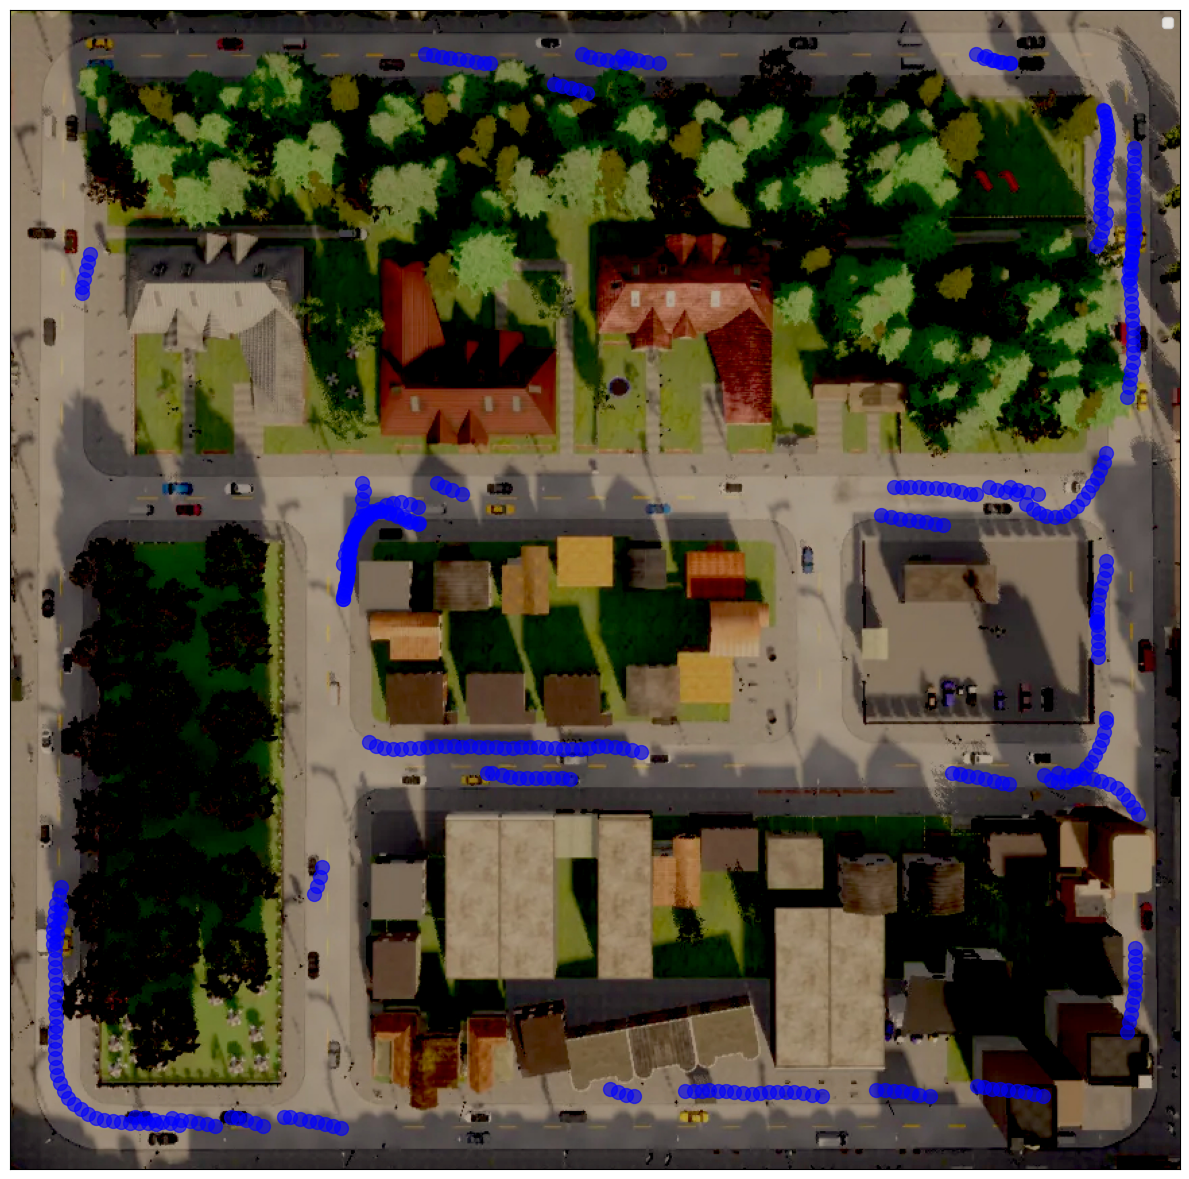

In [31]:
import os


name="DrQLearner"
base_path = f"maps/{name}"
locations=[]
# Get all directories recursively
for root, dirs, files in os.walk(base_path):
    for file in files:
        file_path = os.path.join(root, file)
        print(file_path)
        
        with open(file_path, 'rb') as handle:
            dataset = pickle.load(handle)
            # features = dataset["features"]
            # headings = dataset["heading"]
            locations.extend(dataset["locations"])
fig, ax = plot_from_array_data("/home/robotlab/scratch/carla-rl/town02aerial.jpg", locations, save_path="drq_global_map.png")

plt.show()

In [17]:
# import glob
# import pickle

# from src.mapping.topological_map import TopologicalMap

# name="DrQLearner"
# difficulty="hard"
# path=f"maps/{name}/{difficulty}/*"
# # breakpoint()
# locations=[]
# mapper=TopologicalMap()
# for m in glob.glob(path):
#     with open(m, 'rb') as handle:
#         dataset=pickle.load(handle)
  
#     features=dataset["features"]
#     headings=dataset["heading"]
#     locs=dataset["locations"]
#     for ix in range(len(features)):
#             image,heading,loc = features[ix],headings[ix],locs[ix] 
#             if len(mapper.des_nodes)>0:
#                 indices,distances=mapper.flann.nn_index(image,num_neighbors=1)
#                 if distances and distances[-1]<1e-3:
#                         continue
#                 locations.append(loc)
#                 mapper.update(image,heading) #build map